# Revenue Trends Analysis

- Plot monthly MRR over time.
- Calculate net revenue retention (new MRR minus churned MRR). Identify months with unusual spikes or dips.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import seaborn as sns

In [3]:
%load_ext sql
%config SqlMagic.autopandas = True
%sql duckdb://

Connecting to 'duckdb://'

In [4]:
%%sql
CREATE OR REPLACE TABLE subscriptions AS SELECT * FROM read_csv_auto('data/subscriptions.csv');

Running query in 'duckdb://'

,Success


In [5]:
%%sql
CREATE OR REPLACE TABLE monthly_revenue AS SELECT * FROM read_csv_auto('data/monthly_revenue.csv');

Running query in 'duckdb://'

,Success


In [43]:
%%sql result_8 <<

SELECT month, 
       total_mrr
  FROM monthly_revenue;

Running query in 'duckdb://'

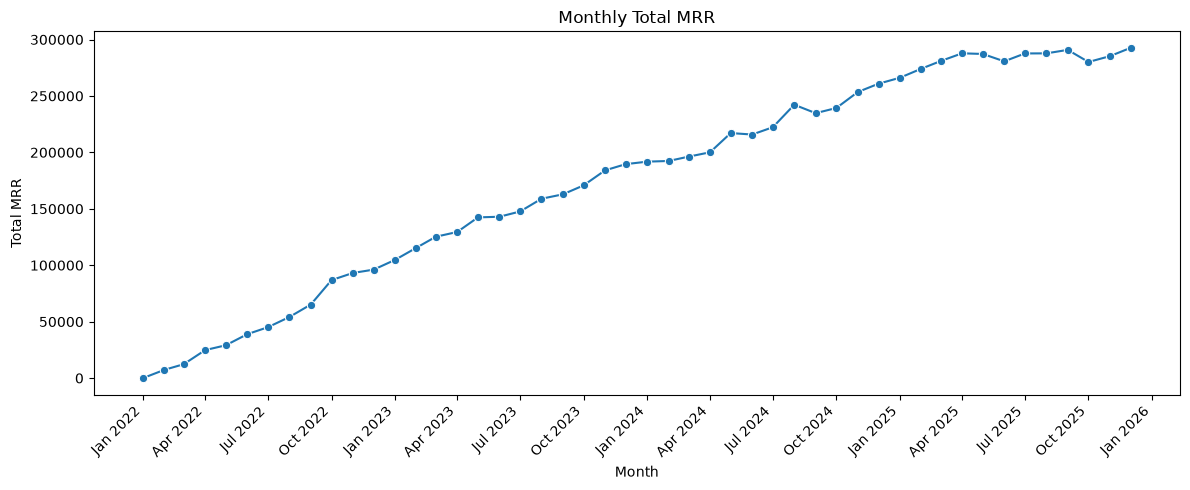

In [44]:
result_8["month"] = pd.to_datetime(result_8["month"])
result_8 = result_8.sort_values("month")

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=result_8, x="month", y="total_mrr", marker="o", ax=ax)

ax.set_title("Monthly Total MRR")
ax.set_xlabel("Month")
ax.set_ylabel("Total MRR")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
%%sql result_9 <<

WITH new_mrr AS (
    SELECT DATE_TRUNC('month', signup_date) AS month,
           SUM(monthly_revenue) AS new_mrr
      FROM subscriptions
    GROUP BY month
),

churned_mrr AS (
    SELECT DATE_TRUNC('month', churn_date) AS month,
           SUM(monthly_revenue) AS churned_mrr
      FROM subscriptions
     WHERE churned = true
    GROUP BY month
)

SELECT COALESCE(n.month, c.month) AS month,
       COALESCE(n.new_mrr, 0) AS new_mrr,
       COALESCE(c.churned_mrr, 0) AS churned_mrr,
       COALESCE(n.new_mrr, 0) - COALESCE(c.churned_mrr, 0) AS net_new_mrr
  FROM new_mrr n
  FULL OUTER JOIN churned_mrr c USING (month)
 ORDER BY month;

In [ ]:
result_9["month"] = pd.to_datetime(result_9["month"])
result_9 = result_9.sort_values("month")
negative_months = result_9[result_9["net_new_mrr"] < 0]

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(result_9["month"], result_9["new_mrr"], width=20, label="New MRR", color="#4C72B0")
ax.bar(result_9["month"], -result_9["churned_mrr"], width=20, label="Churned MRR", color="#C44E52")
ax.plot(result_9["month"], result_9["net_new_mrr"], color="black", marker="o", linewidth=2, label="Net New MRR")
ax.scatter(
    negative_months["month"], negative_months["net_new_mrr"],
    color="gold", edgecolor="black", linewidth=1.2, s=110, zorder=5, label="Negative Net New MRR",
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Monthly New vs. Churned MRR, with Net New MRR")
ax.set_xlabel("Month")
ax.set_ylabel("MRR ($)")
ax.legend()

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
%%sql result_10 <<

SELECT CASE WHEN DATE_TRUNC('month', churn_date) IN
            ('2023-12-01','2024-05-01','2024-08-01','2025-05-01','2025-09-01')
       THEN 'Drop-off months' ELSE 'Other months' END AS period,
       churn_reason,
       COUNT(*) AS n
  FROM subscriptions
 WHERE churned = true
 GROUP BY period, churn_reason
 ORDER BY period, n DESC;

In [ ]:
reason_pivot = result_10.pivot(index="churn_reason", columns="period", values="n").fillna(0)
reason_pct = reason_pivot.div(reason_pivot.sum(axis=0), axis=1) * 100
reason_pct = reason_pct.sort_values("Drop-off months", ascending=False)
reason_pct["diff_pp"] = reason_pct["Drop-off months"] - reason_pct["Other months"]

reason_order = reason_pct.index.tolist()
reason_pct_long = reason_pct.reset_index().melt(
    id_vars=["churn_reason", "diff_pp"], value_vars=["Drop-off months", "Other months"],
    var_name="period", value_name="pct",
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=reason_pct_long, x="churn_reason", y="pct", hue="period",
    order=reason_order, hue_order=["Drop-off months", "Other months"], ax=ax,
)

ax.set_title("Churn Reason Mix: Drop-off Months vs. Other Months (% of Churns)")
ax.set_xlabel("Churn Reason")
ax.set_ylabel("% of Churned Customers")
ax.legend(title="Period")
plt.xticks(rotation=30, ha="right")

dropoff_container = ax.containers[0]
other_container = ax.containers[1]
for dropoff_bar, other_bar, reason in zip(dropoff_container, other_container, reason_order):
    diff = reason_pct.loc[reason, "diff_pp"]
    if diff <= 0:
        continue
    top = max(dropoff_bar.get_height(), other_bar.get_height())
    x_center = (dropoff_bar.get_x() + dropoff_bar.get_width() + other_bar.get_x()) / 2
    dropoff_bar.set_edgecolor("darkred")
    dropoff_bar.set_linewidth(2.5)
    ax.text(
        x_center, top + 0.8, f"+{diff:.1f}pp",
        ha="center", color="darkred", fontsize=10, fontweight="bold",
    )

plt.tight_layout()
plt.show()


### Why the Drop-off Months Happened: Churn Reason Shifted

Comparing the churn_reason mix in the 5 negative-net-new-MRR months (Dec 2023, May 2024, Aug 2024, May 2025, Sep 2025; n=46) against all other months (n=267) shows the drop-offs weren't just "more churn of the usual kind" — the *mix* of reasons shifted. Four reasons are over-represented in the drop-off months: **Budget Cuts (+8.2pp, 23.9% vs. 15.7%)**, **No Longer Needed (+5.0pp)**, **Poor Support (+4.7pp)**, and **Missing Features (+2.9pp)**. Three reasons are under-represented: Price Too High (-3.8pp), Company Closed (-7.8pp), and Switched Competitor (-9.1pp).

Budget Cuts and No Longer Needed point to external/macro pressure on customers' own budgets — not something the product directly controls. **Poor Support and Missing Features are different: they're reasons the business can act on directly**, and they're worth digging into further using the other fields in `subscriptions` (`support_tickets_12mo`, `nps_score`, `feature_usage_pct`, `plan`) to see whether these drop-off-month churners looked different on those metrics before they left, and whether the pattern concentrates in a particular plan or segment.

Caveat: with only 46 churns across 7 reasons in the drop-off bucket, these percentage-point differences are directional, not statistically confirmed — several cells are in the single digits.

## Deep Dive: Poor Support and Missing Features Churners

Poor Support and Missing Features are the two over-represented drop-off-month reasons the business can actually act on. Before assuming the usual engagement signals (`support_tickets_12mo`, `nps_score`, `feature_usage_pct`) explain this, we compare those metrics for customers who churned citing these two reasons against customers who churned for any other reason.

In [ ]:
%%sql result_11 <<

SELECT churn_reason, plan, company_size, support_tickets_12mo, nps_score, feature_usage_pct
  FROM subscriptions
 WHERE churned = true;

In [ ]:
target_reasons = ["Poor Support", "Missing Features"]
result_11["group"] = result_11["churn_reason"].apply(
    lambda r: "Poor Support / Missing Features" if r in target_reasons else "Other reasons"
)

metrics = ["support_tickets_12mo", "nps_score", "feature_usage_pct"]
summary = result_11.groupby("group")[metrics].agg(["mean", "median", "count"])
summary

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    sns.boxplot(data=result_11, x="group", y=metric, ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("Support Tickets, NPS, and Feature Usage: Poor Support/Missing Features Churners vs. Other Churners")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

group_a = result_11[result_11["group"] == "Poor Support / Missing Features"]
group_b = result_11[result_11["group"] == "Other reasons"]

for metric in metrics:
    stat, pvalue = mannwhitneyu(group_a[metric], group_b[metric])
    print(f"{metric}: Mann-Whitney U = {stat:.1f}, p = {pvalue:.4f}")

### Deep Dive Result: The Usual Engagement Metrics Don't Explain It

None of the three candidate signals distinguish Poor Support/Missing Features churners from other churners: `support_tickets_12mo` (7.18 vs. 7.45 mean, p = 0.67), `nps_score` (3.29 vs. 2.95 mean, p = 0.13), and `feature_usage_pct` (27.9% vs. 27.3% mean, p = 0.79) are all statistically indistinguishable between the two groups. If anything, the direction is counter-intuitive — Poor Support churners don't log more support tickets, and Missing Features churners don't show lower feature usage, than customers who churned for unrelated reasons like Price Too High or Company Closed.

This dataset's quantitative fields simply don't explain *why* these two reasons spiked in the drop-off months — ticket volume, NPS, and usage depth are the wrong lens here. The real answer requires qualitative follow-up that falls outside this data:

- **Poor Support**: pull the actual content of these customers' support tickets (not just the count) to find what specifically went wrong — response time, unresolved issues, agent quality, etc.
- **Missing Features**: go back to these customers directly — via their ticket content or direct user interviews — to find out which specific features they needed and didn't get.

Both are next steps for the CS/product team to run outside this notebook, not something we can resolve further from `subscriptions.csv`.